# Posterior for E. coli local recombination rate and mutation rate using SBI

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from Bio import Phylo
import seaborn as sns
import torch
from torch.distributions import Uniform
import sbi
from sbi.utils.user_input_checks import MultipleIndependent
from sbi.neural_nets import posterior_nn
from sbi.inference import NPE_C
from sbi.analysis import plot_summary
import sys
sys.path.append('../pysimARG')
from discrete_uniform import DiscreteUniform
from LeaveLengthOut_NN import LeaveLengthOut_NN

torch_device = "cpu"

c:\Users\u2008181\likelihood-free\sbi_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load simulation data

Load bacillus gene data and clonal tree.

In [2]:
# Load phylo tree and convert to ClonalTree format
phylo_tree = Phylo.read("../data/ecoli/ecoli_clonal.nwk", "newick")
Phylo.draw_ascii(phylo_tree)

                                          ______________________________ 8
                                         |
  _______________________________________|          ____________________ 0
 |                                       |         |
 |                                       |         |                    , 21
 |                                       |_________|    ________________|
 |                                                 |   |                , 2
 |                                                 |   |                |
 |                                                 |___|                | 26
 |                                                     |
 |                                                     |   _____________ 7
 |                                                     |__|
 |                                                        |_____________ 10
 |
_|                                                                    __ 20
 |                           

In [3]:
x_obs_info_table = pd.read_csv("../data/ecoli/ecoli_block_info.csv", index_col=0)
x_obs_info_table.head()

,Gene_Length,Start_pos,End_pos,Alignment
Gene_ID,,,,
0,1200,605790,606989,True
1,1724,614003,615726,True
2,4601,616186,620786,True
3,6950,606990,613939,True
4,3797,601974,605770,True


In [4]:
drop_col = range(16, 32)

In [5]:
x_obs_df = pd.read_csv("../data/ecoli/ecoli_block_summary_stats.csv", header=None)
x_obs_np = x_obs_df.to_numpy()
x_obs_np = np.delete(x_obs_np, drop_col, axis=1)
x_obs_torch = torch.tensor(x_obs_np, device=torch_device)
x_obs_torch = x_obs_torch.to(torch.float32)
x_obs_torch.shape, x_obs_torch.dtype

(torch.Size([836, 30]), torch.float32)

### Delete observations with no signal

In [6]:
x_obs_info_table

,Gene_Length,Start_pos,End_pos,Alignment
Gene_ID,,,,
0,1200,605790,606989,True
1,1724,614003,615726,True
2,4601,616186,620786,True
3,6950,606990,613939,True
4,3797,601974,605770,True
...,...,...,...,...
761_0,5476,1504811,1510286,True
761_1,5475,1510287,1515761,True
762,4170,1541972,1546141,True


In [7]:
too_large_length = np.where(x_obs_info_table['Gene_Length'] > 10000)[0]
too_large_length

array([], dtype=int64)

In [8]:
no_signal_id = np.where(x_obs_np[:, 17] == 0)[0]
no_signal_id.shape, no_signal_id[:10]

((0,), array([], dtype=int64))

Ignore the observations that have too large gene length. But there is no observations with no signal.

## Load simulation data

In [9]:
theta1 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/theta1.csv', delimiter=",")
x1 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/x1.csv', delimiter=",")
nrow1 = x1.shape[0]

theta2 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/theta2.csv', delimiter=",")
x2 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/x2.csv', delimiter=",")
nrow2 = x2.shape[0]

theta3 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/theta3.csv', delimiter=",")
x3 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/x3.csv', delimiter=",")
nrow3 = x3.shape[0]

theta4 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/theta4.csv', delimiter=",")
x4 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/x4.csv', delimiter=",")
nrow4 = x4.shape[0]

theta5 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/theta5.csv', delimiter=",")
x5 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/x5.csv', delimiter=",")
nrow5 = x5.shape[0]

theta6 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/theta6.csv', delimiter=",")
x6 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/x6.csv', delimiter=",")
nrow6 = x6.shape[0]

theta7 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/theta7.csv', delimiter=",")
x7 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/x7.csv', delimiter=",")
nrow7 = x7.shape[0]

theta8 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/theta8.csv', delimiter=",")
x8 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/x8.csv', delimiter=",")
nrow8 = x8.shape[0]

theta9 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/theta9.csv', delimiter=",")
x9 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/x9.csv', delimiter=",")
nrow9 = x9.shape[0]

theta10 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/theta10.csv', delimiter=",")
x10 = np.loadtxt('../data/ecoli/ClonalOrigin_sim/x10.csv', delimiter=",")
nrow10 = x10.shape[0]

x = np.vstack([x1, x2, x3, x4, x5, x6, x7, x8, x9, x10])
x = np.delete(x, drop_col, axis=1)
theta = np.vstack([theta1[:nrow1], theta2[:nrow2], theta3[:nrow3], theta4[:nrow4], theta5[:nrow5],
                   theta6[:nrow6], theta7[:nrow7], theta8[:nrow8], theta9[:nrow9], theta10[:nrow10]])

print(theta.shape, x.shape)

(57100, 3) (57100, 30)


In [10]:
theta = torch.tensor(theta, device=torch_device)
theta = theta.to(torch.float32)
theta_numpy = theta.cpu().numpy()

x = torch.tensor(x, device=torch_device)
x = x.to(torch.float32)
x_numpy = x.cpu().numpy()

### Find out-of-range observations

In [11]:
ignore_indices = []
no_segregation = []
out_stats = dict()
for i in range(x_obs_torch.shape[0]):
    ignore_i = False
    out_index = []
    for j in range(30):
        max_j = torch.max(x[:, j])
        min_j = torch.min(x[:, j])
        obs_j = x_obs_torch[i, j]
        if obs_j < min_j or obs_j > max_j:
            ignore_i = True
            out_index.append(j)
        if j == 17 and obs_j == 0:
            no_segregation.append(i)
    if ignore_i or torch.isnan(x_obs_torch[i, :]).any():
        print(f"Observation {i} is outside the range of simulated data.")
        ignore_indices.append(i)
        out_stats[i] = out_index

Observation 5 is outside the range of simulated data.
Observation 22 is outside the range of simulated data.
Observation 31 is outside the range of simulated data.
Observation 38 is outside the range of simulated data.
Observation 57 is outside the range of simulated data.
Observation 60 is outside the range of simulated data.
Observation 63 is outside the range of simulated data.
Observation 108 is outside the range of simulated data.
Observation 120 is outside the range of simulated data.
Observation 136 is outside the range of simulated data.
Observation 146 is outside the range of simulated data.
Observation 149 is outside the range of simulated data.
Observation 162 is outside the range of simulated data.
Observation 164 is outside the range of simulated data.
Observation 261 is outside the range of simulated data.
Observation 308 is outside the range of simulated data.
Observation 345 is outside the range of simulated data.
Observation 362 is outside the range of simulated data.


In [12]:
len(ignore_indices), len(no_segregation), len(out_stats)

(35, 0, 35)

In [13]:
out_index_all = []
for i in range(len(ignore_indices)):
    idx = ignore_indices[i]
    out_index_all += out_stats[idx]

In [14]:
from collections import Counter

integer_counts = Counter(out_index_all)

In [15]:
for i in range(30):
    print(f"Index {i}: {integer_counts[i]}")

Index 0: 0
Index 1: 0
Index 2: 0
Index 3: 0
Index 4: 0
Index 5: 0
Index 6: 0
Index 7: 0
Index 8: 11
Index 9: 5
Index 10: 0
Index 11: 0
Index 12: 15
Index 13: 6
Index 14: 0
Index 15: 0
Index 16: 0
Index 17: 0
Index 18: 0
Index 19: 0
Index 20: 0
Index 21: 0
Index 22: 35
Index 23: 21
Index 24: 0
Index 25: 14
Index 26: 0
Index 27: 0
Index 28: 0
Index 29: 0


## NPE

### Create prior to pass range knowledge to NPE

In [16]:
prior_rho = Uniform(low=torch.tensor([0.0]), high=torch.tensor([0.2]))
prior_theta = Uniform(low=torch.tensor([0.0]), high=torch.tensor([0.1]))
prior_L = DiscreteUniform(low=torch.tensor([100.0]), high=torch.tensor([10000.0]))

prior = MultipleIndependent(
    dists=[prior_rho, prior_theta, prior_L],
    validate_args=False,
    device=torch_device
)

### Using all simulations

In [17]:
embedding_net = LeaveLengthOut_NN(
    input_dim=30,
    num_hiddens=128,
    num_hidden_layers=1,
    num_outputs=2)
neural_posterior = posterior_nn(
    model="nsf",
    embedding_net=embedding_net,
    hidden_features=30,
    num_transforms=8,
    num_bins=5,
    z_score_theta="independent",
    z_score_x="independent"
)

In [18]:
seed = 100
num_posterior_samples=1000

inference = NPE_C(density_estimator=neural_posterior, device=torch_device)
torch.manual_seed(seed)
np.random.seed(seed)

In [19]:
%%time
density_estimator = inference.append_simulations(theta, x).train(
    max_num_epochs=500,
    training_batch_size=100,
    learning_rate=0.0001,
    stop_after_epochs=20,
    clip_max_norm=None
)
posterior = inference.build_posterior(density_estimator)

c:\Users\u2008181\likelihood-free\sbi_env\Lib\site-packages\sbi\inference\trainers\npe\npe_base.py:196: UserWarning: Data has extreme outliers in dimension(s) [8, 9, 10, 11, 12, 13, 16, 20, 25, 26, 27, 28] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


 Neural network successfully converged after 88 epochs.CPU times: total: 24min 21s
Wall time: 24min 47s


c:\Users\u2008181\likelihood-free\sbi_env\Lib\site-packages\sbi\inference\potentials\posterior_based_potential.py:58: UserWarning: The passed prior has no support property, transform will be constructed from mean and std. If the passed prior is supposed to be bounded consider implementing the prior.support property.
  theta_transform = mcmc_transform(


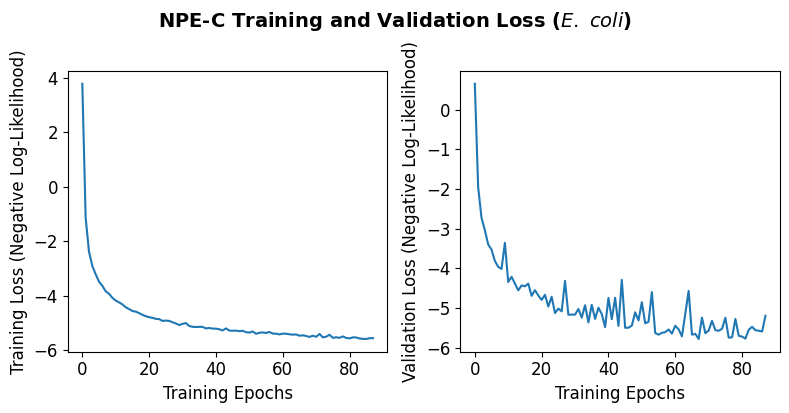

In [20]:
fig, axes = plot_summary(
    inference, 
    tags=["training_loss", "validation_loss"], 
    figsize=(8, 4)
)

axes[0].set_xlabel("Training Epochs", fontsize=12)
axes[0].set_ylabel("Training Loss (Negative Log-Likelihood)", fontsize=12)

axes[1].set_xlabel("Training Epochs", fontsize=12)
axes[1].set_ylabel("Validation Loss (Negative Log-Likelihood)", fontsize=12)

# 2. Put a clean, centered title across the whole figure (with italicized species name)
fig.suptitle(
    r"NPE-C Training and Validation Loss ($\it{E.\ coli}$)", 
    fontsize=14, 
    fontweight="bold", 
    y=1.02
)

plt.tight_layout()
plt.savefig("../output/ecoli_npe_loss.pdf", format="pdf", bbox_inches="tight")
plt.show()

### Training time

CPU times: total: 24min 21s

Wall time: 24min 47s

In [21]:
s = inference.summary
print(s.keys())
print("Epochs trained:", s["epochs_trained"])
if "epoch_durations_sec" in s:
    print("Total epoch time:", sum(s["epoch_durations_sec"]), "s")

dict_keys(['epochs_trained', 'best_validation_loss', 'validation_loss', 'training_loss', 'epoch_durations_sec'])
Epochs trained: [88]
Total epoch time: 1485.812425851822 s
